# 02 · 我的课表：报名关系、课程查询与微服务协作


## 本章范围与学习路线

用户已经报名或支付，但“我的课程”没有对应课程，因为交易结果还没有转成学习服务维护的课表。本章围绕这个缺口，完成从产品原型、接口设计、数据库建模到消息消费和查询聚合的开发过程。

**来源**：[网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj) 中 `day02-我的课表/讲义/day02-我的课程.pptx`（39页），以及配套资料指向的 [官方 day02-我的课表讲义](https://my.feishu.cn/wiki/wikcnWLvDK8JgXzjQvgfUepUFUb)。整理日期：2026-10-09。原讲义代码保留关键逻辑，标注“补充”的方案用于解释边界和完善设计，不代表已在课程仓库实现。

| 顺序 | 任务 | 完成标志 |
| --- | --- | --- |
| 1 | 阅读原型并梳理交互 | 知道课表由报名产生，页面需要哪些字段 |
| 2 | 设计8项课表接口 | 区分 HTTP、MQ 和 Feign 调用 |
| 3 | 建模用户与课程关系 | 分清课程ID与课表ID，明确唯一约束和有效期 |
| 4 | 消费报名成功消息 | 批量添加课表，理解课程信息与有效期来源 |
| 5 | 分页查询我的课表 | 按当前用户查询，并批量补全课程展示信息 |
| 6 | 查询最近学习课程 | 返回课程、最近小节和课表课程数量 |
| 7 | 完成练习接口 | 退款移除、主动删除、学习资格和人数统计 |
| 8 | 自测与联调 | 消息重复、用户隔离、空结果和有效期边界都有预期 |

本章定义 `planStatus`、`weekFreq` 等学习计划字段，但**学习计划与进度上报的具体实现属于第03课**。本文件中的 Java、SQL、YAML 和 Shell 示例供阅读、跟练，不在 Notebook 的 Python 内核执行。


## 报名、课表与学习的业务流程

交易服务管理订单和报名结果，学习服务管理学员能学哪些课程、学到哪里。支付订单是一项交易记录，课表是一项学习关系，两者由报名成功事件关联。

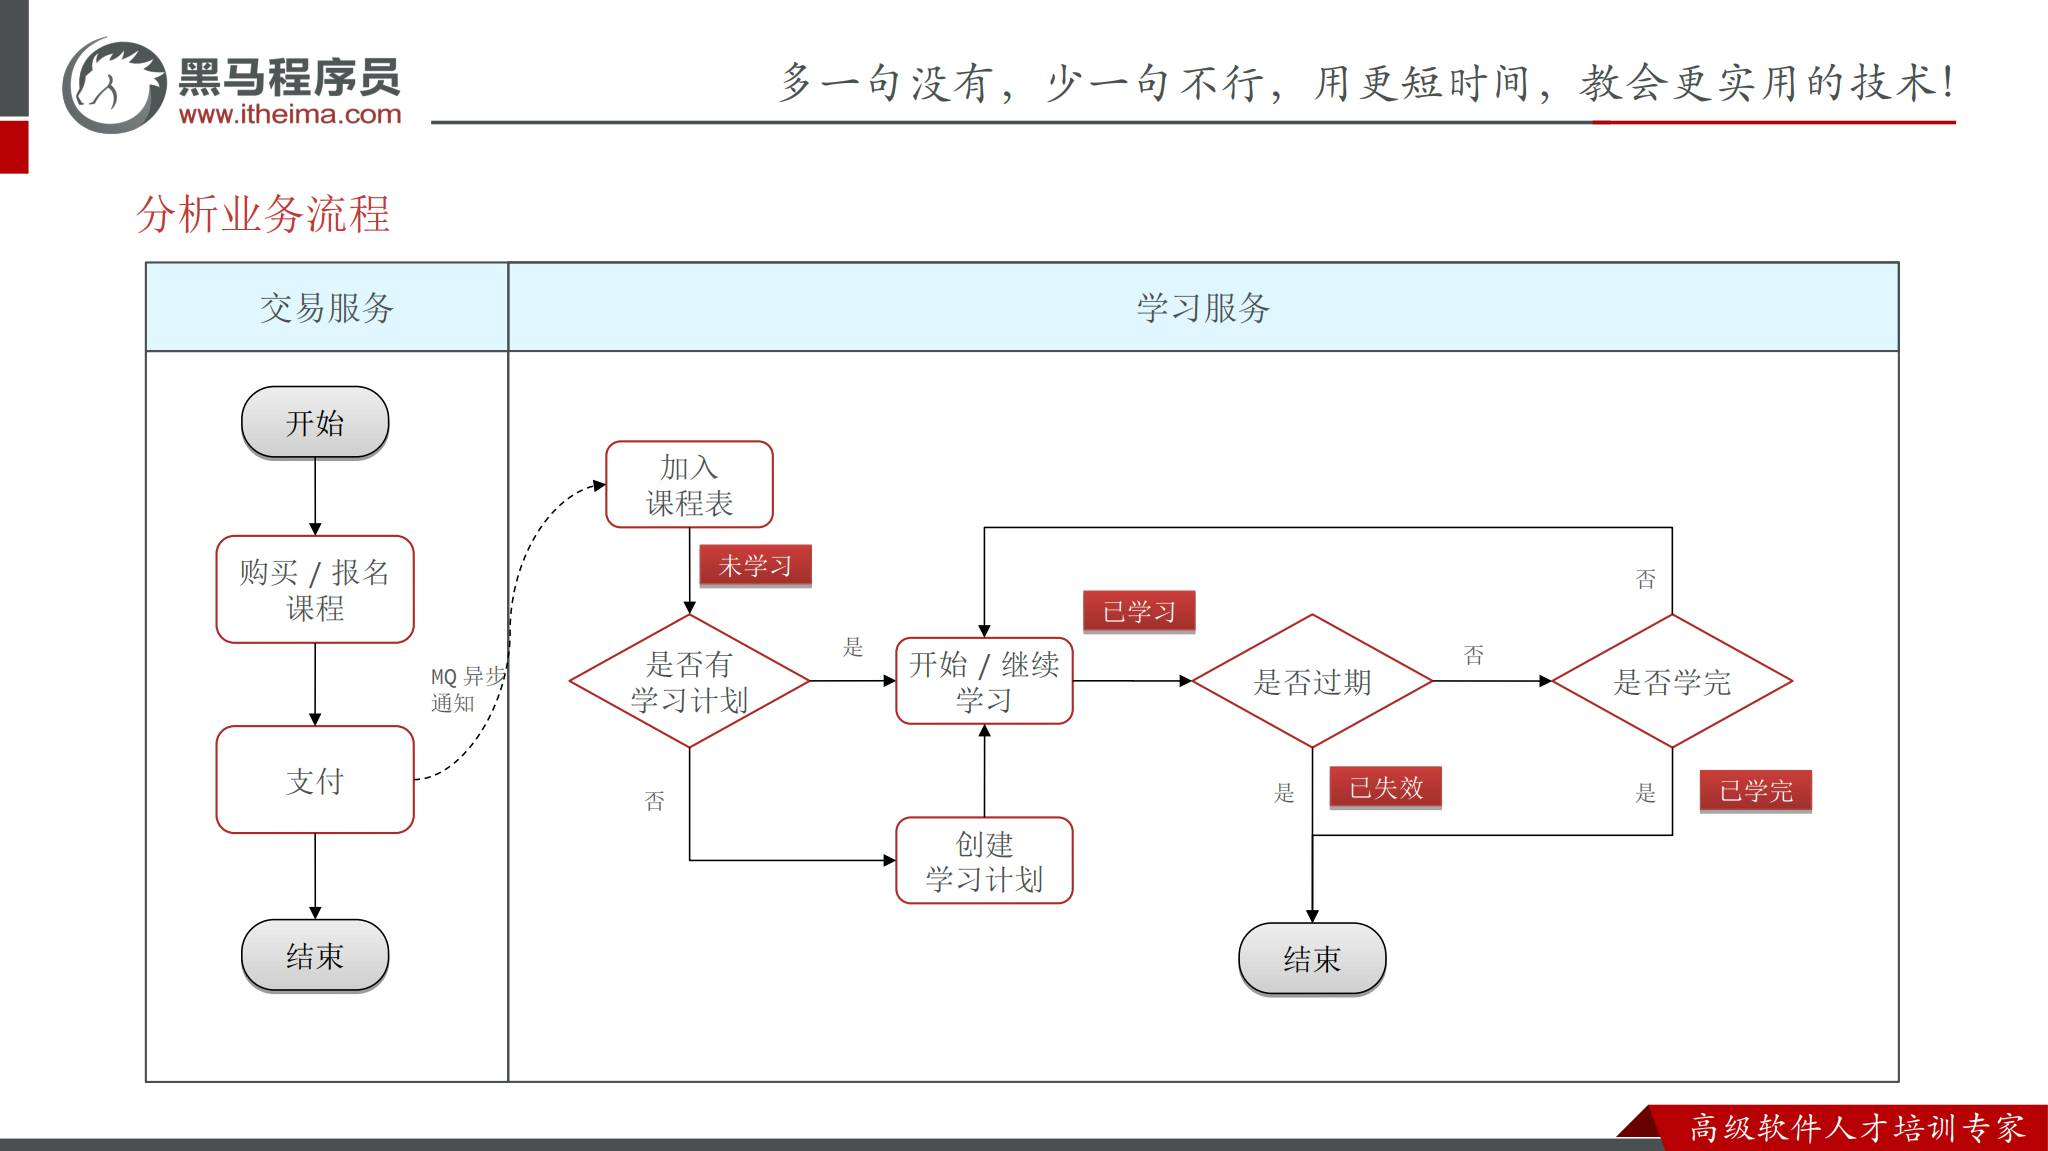

```text
免费报名成功 / 付费课程支付成功
  → 交易服务发布报名成功消息
  → 学习服务消费消息
  → 为用户加入课程，初始为未学习
  → 查询课表，开始或继续学习
  → 后续记录进度、完成状态和学习计划

退款成功 → 交易服务发布退款消息 → 学习服务移除对应课程
```

| 数据 | 维护方 | 解决的问题 |
| --- | --- | --- |
| 订单 | 交易服务 | 买了什么、付了多少钱、交易是否完成 |
| 课程 | 课程服务 | 名称、封面、小节数量、课程有效期等内容属性 |
| 课表 | 学习服务 | 谁报名了哪个课程、学习状态与进度、何时过期 |

> **补充**：MQ 是消息队列，交易服务发布业务事件，学习服务稍后消费。课件中的“立刻加入”描述业务期望，不代表跨服务同步写入或零延迟。报名成功后短暂查不到课表，需要区分正常消费延迟与消息处理失败。


## 从产品原型到接口契约

先读页面说明和交互，再确定接口。页面需要展示什么，决定返回数据；取得这些数据需要什么条件，决定请求参数。跨服务调用则要确认调用方真正需要的结果。

| 分析位置 | 观察内容 | 得到的接口需求 |
| --- | --- | --- |
| 支付、免费报名完成 | 课程进入我的课表 | 消费报名成功消息 |
| 我的课程列表 | 分页、购买时间与最近学习时间排序 | 分页查询课表 |
| 首页悬浮窗、课表顶部 | 最近学到的课程与小节 | 查询正在学习课程 |
| 课程详情 | 买课入口或马上学习，以及进度、有效期 | 查询指定课程学习状态 |
| 已失效课程 | 删除按钮 | 删除当前用户的课表课程 |
| 退款结果 | 取消对应课程学习资格 | 消费退款成功消息 |
| 媒资服务 | 播放前校验资格 | 检查课程是否有效 |
| 课程管理 | 展示报名人数 | 统计课程学习人数 |

接口契约至少包含请求方法、路径、请求参数、返回结构和业务规则。讲义以 YApi 展示这几项信息，工具本身不是核心。已有前端的字段名称和类型已确定，后端不能自行改名后期待前端自动适配。

**补充示例**：页面写“按购买时间排序”，应核实究竟使用支付时间还是课表创建时间。消息可能延迟，两者未必相等。需要把这项约定写入接口说明。


## 八项课表接口与网关路径

课表对外提供查询和删除，对内部服务提供资格与人数查询，报名和退款通过消息接入。HTTP路径中的资源都是 `lessons`。

| 功能 | 调用方式 | 服务内路径 / 消息标识 | 输出 |
| --- | --- | --- | --- |
| 报名、支付后加入课表 | MQ | `ORDER_EXCHANGE` + `ORDER_PAY_KEY` | 无 HTTP 返回值 |
| 分页查询我的课表 | GET | `/lessons/page` | `PageDTO<LearningLessonVO>` |
| 查询最近正在学习的课程 | GET | `/lessons/now` | `LearningLessonVO` 或空结果 |
| 查询指定课程学习状态 | GET | `/lessons/{courseId}` | 当前用户该课程的课表状态 |
| 删除课表课程 | DELETE | `/lessons/{courseId}` | 无业务数据返回 |
| 退款后移除课程 | MQ | `ORDER_EXCHANGE` + `ORDER_REFUND_KEY` | 无 HTTP 返回值 |
| 校验课程学习资格 | GET / Feign | `/lessons/{courseId}/valid` | 有效时返回 `lessonId`，否则为空 |
| 统计课程学习人数 | GET / Feign | `/lessons/{courseId}/count` | `Integer` 人数 |

这些 MQ 常量的实际字符串取值由 `MqConstants` 定义，不凭名称猜测。Feign 是通过接口声明发起远程 HTTP 调用的方式，课程的声明集中在 `tj-api`，学习接口位于 `com.tianji.api.client.learning`。

```text
浏览器：/ls/lessons/{courseId}
  网关按 /ls 选择学习服务，并按路由配置处理前缀
服务内：/lessons/{courseId}
```

> **路径说明**：讲义有时写 `/ls/lessons/...`，接口汇总和 Feign 声明写 `/lessons/...`。前者对应网关入口，后者是服务内映射。完整URL还要带域名与实际路由配置，不能在 Controller 中盲目叠加 `/ls`。


## 分页请求与返回字段

“我的课表”没有本章新增的过滤条件，使用通用分页查询对象 `PageQuery`，按登录身份自动限制用户。

| 请求字段 | 类型 | 用途 |
| --- | --- | --- |
| `pageNo` | Integer | 页码，课程默认1，至少为1 |
| `pageSize` | Integer | 每页数量，课程默认20，至少为1 |
| `sortBy` | String | 排序字段 |
| `isAsc` | Boolean | 是否升序，通用类默认true |

业务实现通过 `query.toMpPage("latest_learn_time", false)` 指定未提供排序时的默认规则：按最近学习时间降序。通用对象的默认值与业务默认排序要一起核对方法实现。

| 返回字段 | 含义 | 来源 |
| --- | --- | --- |
| `total`、`pages`、`list` | 总条数、总页数、当前页数据 | `PageDTO` |
| `id`、`courseId` | 课表ID、课程ID | 学习服务 |
| `createTime`、`expireTime` | 加入时间、过期时间 | 学习服务 |
| `status`、`learnedSections` | 状态、已学习小节数 | 学习服务 |
| `planStatus`、`weekFreq` | 计划状态、每周计划小节数 | 学习服务 |
| `courseName`、`courseCoverUrl`、`sections` | 课程名称、封面、总小节数 | 课程服务 |

修正后的 JSON 结构示例：

```json
{
  "total": 1,
  "pages": 1,
  "list": [
    {
      "id": "101",
      "courseId": "1002101",
      "courseName": "Redis 实战课",
      "courseCoverUrl": "",
      "learnedSections": 0,
      "sections": 20,
      "status": 0,
      "planStatus": 0
    }
  ]
}
```

**补充**：Java数据库ID通常是 `Long`，但前端 JSON 可以约定字符串，避免大整数超过 JavaScript 精确整数范围。这里使用字符串展示ID，实际序列化方式应与项目统一配置一致。

> **勘误**：早期接口示例写 `totalPage`，PPT第22页 `PageDTO` 与第36页示例写 `pages`，应按实际 DTO 和前端契约统一。PPT的 `courseCouverUrl` 改为实现代码里的 `courseCoverUrl`。原示例带注释、缺逗号或尾逗号，不能直接作为合法 JSON 使用。


## 用户与课程的关系模型

同一个用户可以报名多个课程，同一个课程也有多个用户，这是一种多对多关系。课表 `learning_lesson` 用一条记录表达一个用户与一个课程之间的学习关系。

```text
用户                         课表                         课程
user.id ── 一对多 ── learning_lesson ── 多对一 ── course.id
                   id：关系自身的ID
                   user_id：谁
                   course_id：学什么
                   状态、进度、有效期
```

| 标识 | 示例（补充） | 意义 |
| --- | --- | --- |
| `userId` | Jack的2 | 用户身份 |
| `courseId` | Redis课程的1002101 | 课程内容身份 |
| `lessonId` / `id` | 课表记录101 | Jack报名Redis课程的这条关系 |
| `orderId` | 一笔包含两门课的订单 | 交易记录，可以产生多条课表关系 |

课程名称、封面、小节总数由课程服务维护，课表不重复保存这些展示字段。查询时按 `courseId` 调用课程服务补全，这会形成跨服务的数据聚合。

> **补充**：媒资服务的资格接口接收 `courseId`，有效时返回 `lessonId`。不能把这两个ID混用。数据库关系也不意味着跨服务数据库之间必须建立物理外键，服务边界内外的约束要分别设计。


## 课表字段与默认状态

课表必须能回答“是否报名、能否学习、学到哪里”。字段按用途归类，比只记表结构更容易判断接口需要查什么。

| 用途 | 字段 | 初始值 / 规则 |
| --- | --- | --- |
| 关系标识 | `id`、`user_id`、`course_id` | ID由课程工程配置生成，用户和课程不能为空 |
| 学习状态 | `status` | 0未学习、1学习中、2已学完、3已失效 |
| 学习计划 | `plan_status`、`week_freq` | 0无计划、1计划中；频率可为空 |
| 累计进度 | `learned_sections` | 默认0，表示已完成的小节数 |
| 最近学习 | `latest_section_id`、`latest_learn_time` | 还没学习时为空 |
| 生命周期 | `create_time`、`expire_time`、`update_time` | 加入、过期、最后更新的时间 |
| 学完时间 | `finish_time` | PPT表结构新增，未学完时为空 |

每周3天、每天2节，`week_freq=6`，单位是**每周小节数**，不是每周天数。课程总小节数仍由课程服务返回。

`LessonStatus.LEARNING` 是讲义用于“学习中”的枚举。枚举把业务名字映射到数据库数值，避免业务代码四处散落数字1。课程共享的 MyBatis-Plus 枚举配置负责持久化转换，实际枚举类应按配套资料导入。

**补充**：状态是业务分类，过期时间是时间边界。即使 `status` 尚未被任务更新为失效，当前时间超过有效期，也不能仅凭“学习中”放行。


## learning_lesson 表结构与版本差异

数据库以 `(user_id, course_id)` 唯一约束保证一名用户不会出现两条同课程课表。以下按 PPT第26页整理，去掉显示排版中的多余空格，保留可空有效期和学完时间。

```sql
CREATE TABLE IF NOT EXISTS learning_lesson (
  id bigint NOT NULL COMMENT '主键',
  user_id bigint NOT NULL COMMENT '学员id',
  course_id bigint NOT NULL COMMENT '课程id',
  status tinyint DEFAULT '0' COMMENT '0未学习，1学习中，2已学完，3已失效',
  week_freq tinyint DEFAULT NULL COMMENT '每周计划学习的小节数',
  plan_status tinyint NOT NULL DEFAULT '0' COMMENT '0无计划，1计划中',
  learned_sections int NOT NULL DEFAULT '0' COMMENT '已学习小节数',
  latest_section_id bigint DEFAULT NULL COMMENT '最近学习小节id',
  latest_learn_time datetime DEFAULT NULL COMMENT '最近学习时间',
  create_time datetime NOT NULL DEFAULT CURRENT_TIMESTAMP,
  expire_time datetime DEFAULT NULL COMMENT '过期时间',
  finish_time datetime DEFAULT NULL COMMENT '学完时间',
  update_time datetime NOT NULL DEFAULT CURRENT_TIMESTAMP
    ON UPDATE CURRENT_TIMESTAMP,
  PRIMARY KEY (id),
  UNIQUE KEY idx_user_id (user_id, course_id) USING BTREE
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4 COMMENT='学生课程表';
```

讲义使用数据库 `tj_learning`。SQL只定义结构，本笔记没有在电脑上建库或执行它。

| 差异 | 在线讲义 SQL | PPT第26页 |
| --- | --- | --- |
| 有效期 | `expire_time datetime NOT NULL` | `expire_time datetime DEFAULT NULL` |
| 学完时间 | 没有 `finish_time` | 包含 `finish_time` |
| 字符排序规则 | `utf8mb4_0900_ai_ci` | 只指定 `utf8mb4` |

> **勘误**：在线讲义添加方法在有效期为空或不大于0时不赋 `expire_time`，与其非空表约束矛盾。PPT的可空版本避免该插入错误，但“null是否代表永久有效”还须明确业务约定。已有数据库应核对实际DDL和实体，不能用 `CREATE TABLE IF NOT EXISTS` 当作修改旧表的迁移语句。

**补充**：`utf8mb4_0900_ai_ci` 是 MySQL8 的排序规则，旧数据库版本可能不支持。联合唯一索引可以用于按用户查询，但不能代替按学习时间排序的专用索引或按课程统计的索引；是否新增要看查询计划与数据量。


## 功能分支与代码生成

先建立表和接口模型，再生成固定格式的持久层代码，能减少手工重复。课程从 `dev` 创建功能分支：

```bash
git checkout dev
git checkout -b feature-lessons
```

这段命令用于课程项目，不在当前笔记仓库执行。一个仓库中多个模块会同时切换分支。

讲义使用 IDEA 的 MyBatis-Plus 插件连接 `tj_learning`，按表生成 PO、Mapper、Service及实现类。生成后还须人工调整：

```text
tj-learning
├─ domain
│  ├─ po/LearningLesson.java
│  └─ vo/LearningLessonVO.java
├─ mapper/LearningLessonMapper.java
├─ service/ILearningLessonService.java
├─ service/impl/LearningLessonServiceImpl.java
├─ controller/LearningLessonController.java
└─ mq/LessonChangeListener.java
```

| 检查项 | 原因 |
| --- | --- |
| 包路径、类名和父类 | 应符合项目现有结构与 MP 使用方式 |
| PO字段、枚举与ID策略 | 数据库版本不同，生成结果也会不同 |
| Controller路径 | 生成器的默认 CRUD 不一定符合约定 `/lessons` |
| Query、DTO、VO | 数据库表不能自动表达所有接口契约 |
| Service业务 | 幂等性、授权、跨服务查询需要自己实现 |

**补充**：生成器产出的是结构模板，不代表业务已经正确。SQL默认值只有在插入方式让数据库采用默认值时才生效，需核对生成的字段策略和实际SQL。


## 报名成功消息的来源与格式

加入课表由成功事件触发，不由用户随意发起“把某课程加到自己课表”的接口。免费课程也走交易服务：检查课程存在且免费，创建完成状态订单和订单详情，再发送报名成功消息。

```java
// 在线讲义：交易服务中的核心发送逻辑
rabbitMqHelper.send(
    MqConstants.Exchange.ORDER_EXCHANGE,
    MqConstants.Key.ORDER_PAY_KEY,
    OrderBasicDTO.builder()
        .orderId(orderId)
        .userId(userId)
        .courseIds(cIds)
        .build());
```

| 消息字段 | 作用 | 对照说明 |
| --- | --- | --- |
| `orderId` | 关联订单、追踪事件 | 在线讲义发送示例有此字段 |
| `userId` | 课表所属用户 | 在线讲义发送示例有此字段 |
| `courseIds` | 一笔订单中的课程列表 | 需要批量处理，不能只取第一个 |
| `finishTime` | 支付完成时间 | PPT第14、29页有，在线发送示例未设置 |

MQ监听线程没有浏览器请求，不能依赖 `UserContext.getUser()` 获取报名人，必须使用事件中的 `userId`。

> **版本差异**：PPT消息设计包含 `finishTime`，在线代码只有订单、用户和课程列表。若有效期从支付时间计算，消费者需要发送方提供可靠支付时间；若按加入课表时间计算，则使用消费时确定的加入时间。不能编写依赖 `finishTime` 的代码却不检查当前 DTO 与发送方是否传了它。


## RabbitMQ 监听器与业务分层

监听器负责接收和检查消息，Service负责创建课表。原讲义的关键代码，省略包名、导入与日志：

```java
@Component
@RequiredArgsConstructor
public class LessonChangeListener {
    private final ILearningLessonService lessonService;

    @RabbitListener(bindings = @QueueBinding(
        value = @Queue(value = "learning.lesson.pay.queue", durable = "true"),
        exchange = @Exchange(
            name = MqConstants.Exchange.ORDER_EXCHANGE,
            type = ExchangeTypes.TOPIC),
        key = MqConstants.Key.ORDER_PAY_KEY
    ))
    public void listenLessonPay(OrderBasicDTO order) {
        if (order == null || order.getUserId() == null
                || CollUtils.isEmpty(order.getCourseIds())) {
            return; // 原例还记录错误日志
        }
        lessonService.addUserLessons(order.getUserId(), order.getCourseIds());
    }
}
```

| 元素 | 意义 |
| --- | --- |
| `@RabbitListener` | 声明由监听容器调用的方法 |
| Queue | 保存等待学习服务消费的消息 |
| TOPIC Exchange与RoutingKey | 依绑定规则把报名成功事件路由到队列 |
| `durable=true` | 队列声明为持久队列 |
| Service方法 | 接收 `Long userId, List<Long> courseIds`，处理核心业务 |

**补充**：持久队列不等于消息必然可靠，也不等于业务只处理一次。还要结合消息持久化、发布确认、路由、消费确认与异常重试。原例对坏消息直接返回，在常见自动确认配置下会视为处理结束，需要可追踪记录或隔离队列，不能把数据丢失藏在日志中。


## Feign 课程查询与有效期计算

消息只有用户与课程ID，课表还需要过期时间。课程有效期由 `course-service` 维护，因此学习服务通过 `CourseClient` 查询课程信息。

```text
订单事件：userId + courseIds
  → CourseClient.getSimpleInfoList(courseIds)
  → CourseSimpleInfoDTO：id、validDuration等
  → 一门课构造一条LearningLesson
  → 批量保存
```

在线讲义按 `validDuration` 的**月数**计算：

```java
Integer duration = cInfo.getValidDuration();
LocalDateTime joinedAt = LocalDateTime.now();
if (duration != null && duration > 0) {
    lesson.setCreateTime(joinedAt);
    lesson.setExpireTime(joinedAt.plusMonths(duration));
}
```

`plusMonths(1)` 是日历月份加1，不等于固定30天。月末日期的计算也按日历调整，业务要明确日期和时区。

| 时间 | 含义 | 不应混用的场景 |
| --- | --- | --- |
| 课程售卖截止时间 | 还能否报名购买 | 不能直接当作已购学员的学习截止时间 |
| 支付完成时间 | 交易何时成功 | 消费延迟时早于课表创建 |
| 课表加入时间 | 学习关系何时建立 | 讲义用它加有效月数 |
| 课表过期时间 | 学员何时失去时间上的学习资格 | 无期限课程需统一null规则 |

> **补充**：同一订单的课程建议复用一次确定的加入时间；重放消息时保留第一次结果，不能每次消费都重置有效期。课程服务只返回部分ID时，应判断是否完整匹配消息，避免一笔订单只加入部分课程却认为成功。


## 批量添加课表的核心实现

一笔订单可能含多门课，需要一次查询、逐条构造、批量保存。下面保留在线讲义的方法主体：

```java
@Override
@Transactional
public void addUserLessons(Long userId, List<Long> courseIds) {
    List<CourseSimpleInfoDTO> infos = courseClient.getSimpleInfoList(courseIds);
    if (CollUtils.isEmpty(infos)) {
        log.error("课程信息不存在，无法添加到课表");
        return;
    }
    List<LearningLesson> lessons = new ArrayList<>(infos.size());
    for (CourseSimpleInfoDTO info : infos) {
        LearningLesson lesson = new LearningLesson();
        Integer duration = info.getValidDuration();
        if (duration != null && duration > 0) {
            LocalDateTime now = LocalDateTime.now();
            lesson.setCreateTime(now);
            lesson.setExpireTime(now.plusMonths(duration));
        }
        lesson.setUserId(userId);
        lesson.setCourseId(info.getId());
        lessons.add(lesson);
    }
    saveBatch(lessons);
}
```

默认状态与进度由实体、插入策略和数据库默认值协作完成。验证时应查看实际落库值，而不是只看 PO中没有写这些字段。

`@Transactional` 在常规事务配置下让本次数据库批量写入具有事务性，不自动让远程课程查询、MQ确认与数据库提交成为同一个事务。

> **原例限制**：该方法没有完整体现 PPT要求的幂等性。课程查询返回空时直接结束，坏消息也可能被确认；返回部分课程、重复插入、无期限课程与非空旧DDL，都需要另行明确处理。本章保留原理与关键代码，补充方案见下一节。


## 重复消息、唯一约束与幂等性

消费者可能处理成功后尚未确认就中断，MQ会再次投递。幂等性要求重复处理同一业务事件后，结果仍与处理一次相同。

```text
第一次：报名事件 → 插入(userId=2, courseId=1002101) → 成功
第二次：同一事件 → 保留已有课表及进度 → 同样完成
```

| 处理方式 | 问题或效果 |
| --- | --- |
| 直接重复 `saveBatch` | 联合唯一键可能报错，引发反复重试 |
| 先查已有，再插未有 | 减少重复，但并发时仍可能同时查到不存在 |
| 唯一约束 + 明确处理重复冲突 | 为并发情况提供最后防线 |
| 无条件更新已有课表 | 可能把进度或有效期重置，破坏幂等性 |
| 消息处理记录 / 业务版本 | 可追踪事件处理，辅助处理退款等复杂生命周期 |

**补充实现思路**：校验事件与课程列表，去重课程ID，批量查询已有关系，只新增缺失项。插入冲突时确认确实是同一用户同一课程的已完成报名，再按已处理处理，不把其他数据库故障吞掉。

两个场景要分别设计：同一报名消息重放，应保留已有进度；用户退款后重新报名，应建立新的有效学习关系。如果只在退款时物理删除、随后旧报名消息迟到，还可能错误恢复资格。因此不能把“先查再插 + 唯一键”当作解决所有消息乱序的完整方案。

**面试提示**：唯一键保证不重复存储，不保证重复消息能成功结束。消费者需要业务幂等处理，同时区分消息重复和报名/退款事件乱序。


## 网关鉴权与登录用户传递

“我的课表”必须按当前登录用户查询。让前端传任意 `userId`，会把身份判断交给不可信输入。课程把 JWT校验集中到网关，再向下游传内部用户信息。

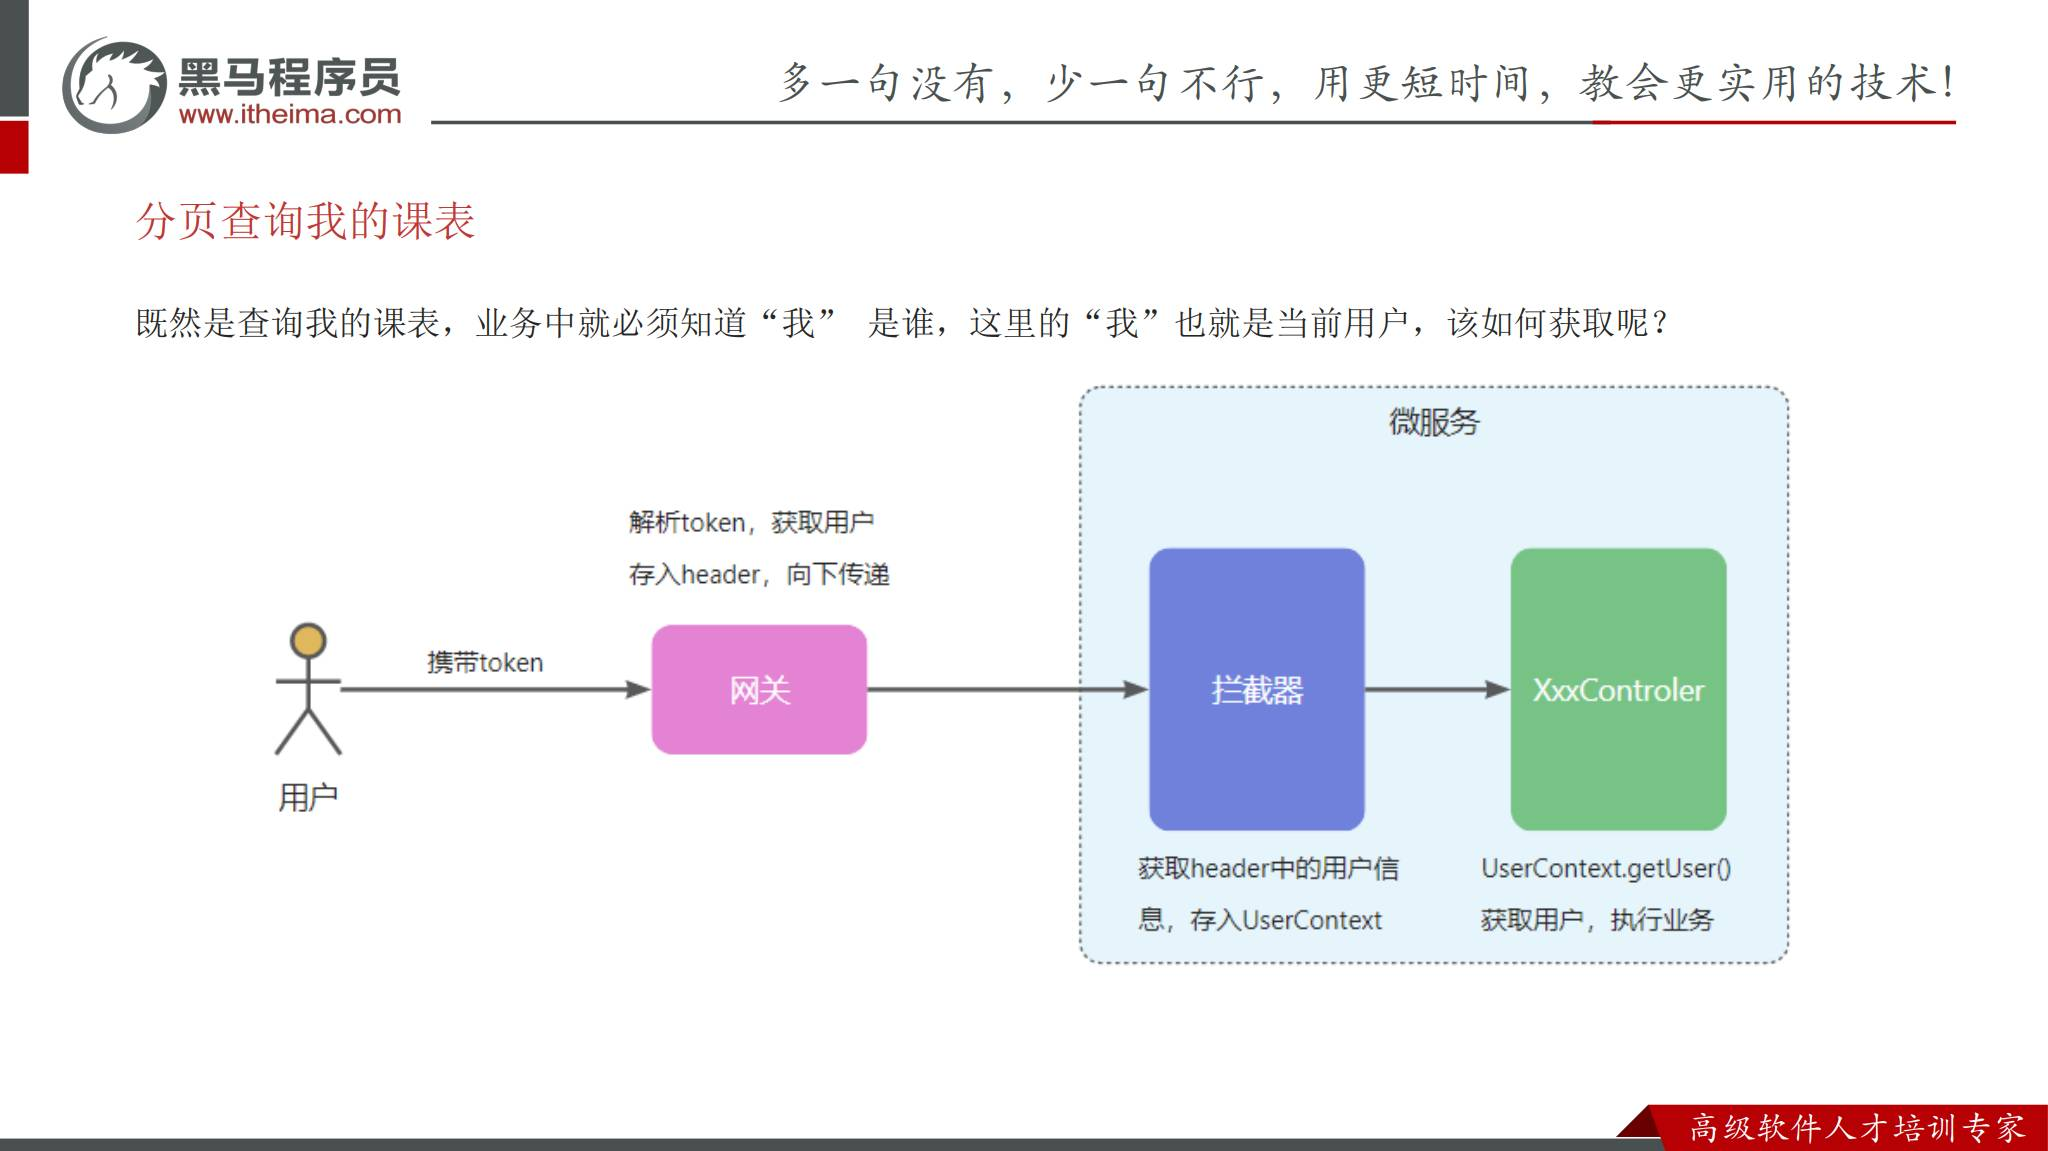

```text
浏览器携带token
  → tj-gateway AccountAuthFilter校验并解析JWT
  → 网关写入内部身份请求头
  → 微服务 UserInfoInterceptor读取请求头
  → UserContext.setUser(userId)
  → Service通过 UserContext.getUser()读取
  → 请求结束 removeUser()
```

JWT 是包含声明并可验证签名的登录凭证。原讲义拦截器用 `JwtConstants.USER_HEADER` 读取身份头，上一章测试所用的头是 `user-info`，具体值仍以工程常量为准。

`UserInfoInterceptor` 在 `tj-auth-resource-sdk` 中共享，负责 MVC请求侧的身份提取。网关过滤器与服务拦截器职责不同：前者校验凭证，后者读取可信内部身份。

> **补充**：公网客户端自行传来的身份头不能当成登录依据，入口应覆盖或清理它，并限制直接访问内部服务。HTTP链路中的用户上下文不会自动传播到MQ监听线程，也不会自动传播到另一个微服务。


## ThreadLocal 上下文与请求结束清理

Controller、Service、工具类都可能需要用户ID，反复传参会增加样板。课程用 `ThreadLocal<Long>` 把ID与当前处理线程关联。

```java
public class UserContext {
    private static final ThreadLocal<Long> TL = new ThreadLocal<>();
    public static void setUser(Long userId) { TL.set(userId); }
    public static Long getUser() { return TL.get(); }
    public static void removeUser() { TL.remove(); }
}
```

原讲义的拦截器在 `preHandle` 解析内部头并调用 `setUser`，在 `afterCompletion` 调用 `removeUser`。

```text
线程A：请求Jack → TL=2 → 执行业务 → remove
线程B：请求Rose → TL=129 → 执行业务 → remove
线程A：下一个请求 → 不应读到Jack上次遗留的2
```

| 场景 | 能否直接使用当前ThreadLocal |
| --- | --- |
| 同一MVC请求、同一线程的业务调用 | 可以 |
| 线程池中的下一个请求 | 只有清理正确才不会遗留身份 |
| 新线程或异步任务 | 默认不会自动继承，需要显式传递与清理 |
| MQ消费 | 应使用消息中的业务用户ID |
| Feign调用另一服务 | 需要调用链中的身份头传递配置 |

> **原例限制与补充**：缺失或非法身份头时，讲义的拦截器仍返回true。它不是完整授权拦截器。“我的课表”等需要登录的服务方法应显式拒绝空用户，再构造查询条件。线程局部存储提供线程隔离，不代表所有异步处理自动安全。

**面试提示**：为何必须remove？Web服务器复用线程，未清理的值会跨请求残留。ThreadLocal绑定线程，业务请求只是借该线程执行，两者生命周期不相同。


## Controller、PageQuery 与 PageDTO

Controller声明接口，Service实现业务，通用分页对象处理重复的分页结构。原讲义的入口：

```java
@Api(tags = "我的课表相关接口")
@RestController
@RequestMapping("/lessons")
@RequiredArgsConstructor
public class LearningLessonController {
    private final ILearningLessonService lessonService;

    @GetMapping("/page")
    @ApiOperation("查询我的课表")
    public PageDTO<LearningLessonVO> queryMyLessons(PageQuery query) {
        return lessonService.queryMyLessons(query);
    }
}
```

`GET`查询参数由Spring绑定到 `PageQuery`，`toMpPage` 将它转成 MyBatis-Plus的 `Page`。`PageDTO` 包含总量、页数和当前页集合，集合元素是用于展示的 `LearningLessonVO`。

```text
PageQuery(pageNo, pageSize, sortBy, isAsc)
  → MP Page<LearningLesson>
  → 课程信息补全
  → PageDTO<LearningLessonVO>
```

**补充**：请求对象上有 `@Min`，不代表Controller一定已启用对应校验，还需核对 `@Valid/@Validated` 等入口配置。限制最大pageSize，并把允许的 `sortBy` 映射到固定列，不能把用户输入直接拼进SQL排序子句。


## 按当前用户分页查询与排序

先分页课表，再补课程信息。这样查询规模只与当前页相关，不必把全部课程拉回来后在内存中分页。

```java
// 在线讲义核心查询
Long userId = UserContext.getUser();
Page<LearningLesson> page = lambdaQuery()
    .eq(LearningLesson::getUserId, userId)
    .page(query.toMpPage("latest_learn_time", false));
List<LearningLesson> records = page.getRecords();
if (CollUtils.isEmpty(records)) {
    return PageDTO.empty(page);
}
```

对应的查询含义：

```sql
SELECT * FROM learning_lesson
WHERE user_id = :currentUserId
ORDER BY latest_learn_time DESC
LIMIT :offset, :pageSize;
```

| 时间列 | 正确含义 |
| --- | --- |
| `create_time` | 课表创建/加入时间，课程界面用于购买时间排序 |
| `latest_learn_time` | 最近学习时间 |
| `expire_time` | 学习资格过期时间 |

> **勘误**：PPT和讲义接口表把 `create_time` 写成过期时间，或把最近学习列写成 `last_learn_time/lastest_learn_time`。以DDL、PO和Controller说明为准，本章统一 `create_time` 与 `latest_learn_time`。

**补充场景**：两条记录学习时间相同，建议增加ID作为稳定次序；未学习记录时间为空，要确定在当前数据库排序下如何展示。请求页码超过末页时，保留真实总数与页数，不因当前页为空而把总条数改成0。


## 批量补全课程信息与 VO 聚合

课表PO没有课程名称、封面和总小节数，必须向课程服务查询。逐条循环发远程请求会形成N+1调用，增加延迟与故障机会。讲义先提取当前页课程ID，批量查询，再转成Map。

```java
Set<Long> courseIds = records.stream()
    .map(LearningLesson::getCourseId)
    .collect(Collectors.toSet());
List<CourseSimpleInfoDTO> infos = courseClient.getSimpleInfoList(courseIds);
Map<Long, CourseSimpleInfoDTO> byId = infos.stream()
    .collect(Collectors.toMap(CourseSimpleInfoDTO::getId, info -> info));

List<LearningLessonVO> result = new ArrayList<>(records.size());
for (LearningLesson lesson : records) {
    LearningLessonVO vo = BeanUtils.copyBean(lesson, LearningLessonVO.class);
    CourseSimpleInfoDTO info = byId.get(lesson.getCourseId());
    vo.setCourseName(info.getName());
    vo.setCourseCoverUrl(info.getCoverUrl());
    vo.setSections(info.getSectionNum());
    result.add(vo);
}
return PageDTO.of(page, result);
```

上面按原讲义抽出主体，原方法会先检查远程集合是否为空并抛 `BadRequestException`。Map关联不依赖远程返回顺序，最终仍按课表分页顺序组装结果。

```text
当前页课表：[课程C、课程A]
课程服务返回：[课程A信息、课程C信息]
转换Map：{A:信息A, C:信息C}
按课表组装：[课程C的VO、课程A的VO]
```

> **原例限制**：检查整个集合非空，不足以保证每个课程都有返回。单个ID缺失时 `byId.get` 仍可能为空。应约定缺失课程是保留占位、跳过还是报业务错误，并处理远程重复ID与失败，避免空指针。跳过会影响页面条数与总量含义，也必须说明。

**面试提示**：分页跨服务聚合先在本地按所属用户分页，再批量补全展示字段，可控制调用量。远程数据不一定完整，不能把两个集合按下标拼接。


## 查询最近正在学习的课程

首页悬浮窗和个人中心需要让用户继续上次学习。它不是“最后买的课”，而是在学习中课程里取最近学习的一条。

```java
// 在线讲义核心筛选
LearningLesson lesson = lambdaQuery()
    .eq(LearningLesson::getUserId, UserContext.getUser())
    .eq(LearningLesson::getStatus, LessonStatus.LEARNING.getValue())
    .orderByDesc(LearningLesson::getLatestLearnTime)
    .last("limit 1")
    .one();
if (lesson == null) {
    return null;
}
```

然后补全三类数据：

| 内容 | 讲义来源或调用 |
| --- | --- |
| 课程名称、封面、总小节数 | `courseClient.getCourseInfoById(courseId, false, false)` |
| 当前用户课表课程总数 `courseAmount` | 对 `user_id` 条件执行count |
| 最近小节名称与序号 | `catalogueClient.batchQueryCatalogue(...)` |

```java
List<CataSimpleInfoDTO> items = catalogueClient.batchQueryCatalogue(
    CollUtils.singletonList(lesson.getLatestSectionId()));
if (!CollUtils.isEmpty(items)) {
    CataSimpleInfoDTO item = items.get(0);
    vo.setLatestSectionName(item.getName());
    vo.setLatestSectionIndex(item.getCIndex());
}
```

`CataSimpleInfoDTO` 包含 `Long id`、`String name`、`Integer cIndex`，`cIndex` 是不含章序号的小节序号。最近小节ID为空时应跳过查询。没有学习中课程时，原例直接返回null，前端应按统一空结果约定展示。

> **勘误与补充**：PPT把 `latestSectionName` 写成int，实际是String。课表人数和课程数量的count类型随MP版本变化，不能盲目沿用原例 `Integer`。`last("limit 1")` 的文本必须固定，不能接收用户输入。可增加稳定排序和有效期校验，避免展示已经失效但状态未更新的课程。


## 查询指定课程的学习状态

课程详情要判断当前用户是否已经报名，并在已报名时展示状态、进度和有效期。查询必须同时使用当前用户ID和路径中的课程ID。

```text
GET /lessons/{courseId}
  → 获取当前用户
  → WHERE user_id = 当前用户 AND course_id = 路径课程
  → 未找到：按契约返回空
  → 找到：转换LearningLessonVO并返回
```

讲义练习返回结构整理为合法JSON：

```json
{
  "id": "10",
  "courseId": "1002101",
  "status": 1,
  "learnedSections": 5,
  "createTime": "2023-02-12",
  "expireTime": "2023-12-12",
  "planStatus": 1
}
```

这些日期是讲义历史示例，真实数据类型与格式以VO及序列化配置为准。PPT部分表格写 `LocalDate`，在线正文与PO示例使用 `LocalDateTime`，需确认接口是否保留时分秒。

**补充**：只查 `course_id` 会把别人的报名关系返回给当前用户。这个接口提供展示状态，不应直接代替视频播放资格检查；已有课表关系也可能已过期。


## 退款成功后的课表移除

退款结果分为处理中、成功和失败，只有**退款成功**才触发取消相应课程资格。交易服务的 `RefundApplySerivceImpl.handleRefundResult` 更新退款与子订单状态后发送消息，类名按原讲义保留。

```java
// 原讲义退款成功分支里的消息
rabbitMqHelper.send(
    MqConstants.Exchange.ORDER_EXCHANGE,
    MqConstants.Key.ORDER_REFUND_KEY,
    OrderBasicDTO.builder()
        .orderId(refundApply.getOrderId())
        .userId(refundApply.getUserId())
        .courseIds(CollUtils.singletonList(detail.getCourseId()))
        .build());
```

学习服务应监听相应RoutingKey，用**消息中的userId和courseIds**移除对应关系。监听队列应为退款消费者独立声明，具体队列名以实现约定为准。

| 条件 | 应如何处理 |
| --- | --- |
| 一个订单只退某门课 | 只影响消息列出的课程 |
| 退款仍处理中或失败 | 不按成功事件取消资格 |
| 重复退款成功事件 | 已移除视为完成，不反复报错 |
| 旧报名事件迟到 | 需要业务版本或交易状态机制避免恢复已退款资格 |

> **勘误**：原退款发送逻辑的注释写“通知报名成功”，实际是 `ORDER_REFUND_KEY` 的退款事件。不得依这个复制来的注释判断业务含义。原示例设置的审批人UserContext也不是退款学员，消费者应以消息中的 `refundApply.getUserId()` 为准。

**补充**：物理删除、逻辑删除或标记资格失效，对进度保留、统计、重新报名的含义不同。练习可按课件做移除，扩展真实系统时应先确定保留规则。


## 用户主动删除失效课程

退款是交易事件，主动删除是当前用户整理自己的课表。在线讲义练习明确为删除**已失效**课程，DELETE请求不能无限制移除任何课程。

```text
DELETE /lessons/{courseId}
  → 检查当前用户身份
  → 查询该用户该课程关系
  → 检查已失效等允许删除的条件
  → 按用户+课程执行删除或约定的状态更新
```

| 场景 | 规则 |
| --- | --- |
| 他人的课程关系 | 不允许影响 |
| 自己已失效课程 | 按原型允许删除 |
| 有效、正在学习的课程 | 不应仅凭前端按钮状态放行 |
| 关系已经不存在 | 是否视为删除完成，按团队契约统一 |

讲义前面出现“学完后删除”的描述，练习部分限定“已失效”。这两种规则不完全相同，应以产品约定和后端校验统一。**已学完不一定已过期**。

**补充**：删除当前课表可能丢失学习记录关联、改变人数统计或影响重购。不要让一个用于页面整理的操作悄悄承担全部退款和资格撤销语义。


## 学习资格检查与有效期边界

媒资服务播放视频前需要知道是否有权限。课程的Feign契约返回的是有效课表ID，而非布尔值：

```java
@GetMapping("/lessons/{courseId}/valid")
Long isLessonValid(@PathVariable("courseId") Long courseId);
```

输入是课程ID，用户身份由调用链传递。有效时返回 `lessonId`，无报名关系或失效时返回空。课程描述要求检查两项：存在当前用户的课表关系、该关系没有过期。

补充的判断流程：

```text
当前用户缺失 → 拒绝或按身份契约处理
课表不存在 → 无资格
状态已失效 / 已退款撤销 → 无资格
expireTime有值且当前时间达到截止点 → 无资格
其余满足业务约定 → 返回lesson.id
```

> **有效期约定（补充）**：本笔记建议截止时刻起失效，即 `now >= expireTime`。时间等于截止值是否可学要明确。若采用PPT可空DDL，还须规定null是否永久有效，不能仅因为数据库允许空值就自动授予资格。

两个场景要区分：详情页可以展示已过期关系与历史进度；播放资格必须拒绝过期关系。内部Feign调用也需要用户信息传递，本线程的ThreadLocal不会跨网络自动到达学习服务。


## 课程学习人数的统计口径

后台需要展示课程有多少学员，课程服务通过 `LearningClient` 调学习服务的统计接口：

```java
@GetMapping("/lessons/{courseId}/count")
Integer countLearningLessonByCourse(@PathVariable("courseId") Long courseId);
```

最直接的练习查询：

```sql
SELECT COUNT(*)
FROM learning_lesson
WHERE course_id = :courseId;
```

| 口径 | 要计算的数据 |
| --- | --- |
| 当前课表关系数量 | 现存该课程的关系，退款或删除会减少 |
| 当前有学习资格人数 | 再限制资格与有效期 |
| 历史累计报名人数 | 包含历史报名，不能只从当前课表推导 |
| 实际开始学习人数 | 需要学习状态或记录定义 |

讲义称“报名人数”或“学习人数”，却没有在练习中完全定义上述口径。应先选定产品含义，再设计SQL和数据源。不要只给统计方法取一个好听名字就认为数值含义一致。

**补充**：联合索引 `(user_id, course_id)` 的最左列是用户ID，单独按courseId统计可能需要另一索引。查执行计划后再调整，避免重复新增无效索引。Feign返回Integer是课程契约，类型转换要核对溢出与版本。


## 跨服务事务、消费异常与结果一致性

报名关系由交易事件异步产生，交易数据库、MQ和学习数据库各有状态。仅在学习Service加 `@Transactional`，不能保证三个组件一起提交。

| 失败位置 | 可能结果 | 应验证什么（补充） |
| --- | --- | --- |
| 交易提交前发送消息 | 学习服务先处理了最终回滚的交易 | 发送时机与可靠事件方案 |
| 交易成功但消息未送达 | 订单有了，课表缺失 | 发布确认、重发与补偿 |
| 课程服务暂时不可用 | 监听失败，尚未加入课表 | 超时、异常上抛、重试及隔离 |
| 写库成功但确认前中断 | 消息重投，重复处理 | 幂等处理 |
| 部分课程未返回 | 课表不完整 | 列表完整性与整批事务策略 |
| 退款与报名消息乱序 | 最终资格与交易结果不一致 | 事件版本、状态核对与补偿 |

事务内正常返回通常意味着不会因该返回而回滚。原例“查不到课程就记录日志并return”，可能把一个没有完成的业务当成消费完成，应分清**永久坏数据**和**临时依赖失败**。

**补充方案**：需要可靠交付时，可用事务后发布、可靠本地事件记录/Outbox、消息确认与补偿对账组合。Outbox是在本地事务中同时记录业务变化和待发送事件，再由后台可靠发布。这里解释设计范围，没有替课程示例宣称已具备这些机制。


## 自测与联调的验收场景

按消息写入、用户查询、资格检查分别验证，再做从页面到服务的联调。下面是跟练验收案例，没有在本次笔记整理过程中执行课程系统。

| 场景 | 预期结果 |
| --- | --- |
| 免费报名一门课程 | 一条课表，初始进度0 |
| 支付包含多门课的订单 | 每门课各一条关系，所属用户一致 |
| 重复消费报名消息 | 无重复关系，无进度与有效期重置 |
| 另一用户查询课表 | 只能看到自己的课表 |
| 未登录调用我的课表 | 按认证约定拒绝，不查询他人数据 |
| 第一页、末页、超出末页 | 列表正确，总量与页数保留真实值 |
| 批量课程返回顺序不同 | VO仍保持课表原排序 |
| 课程信息部分缺失 | 按明确契约处理，不发生空指针 |
| 没有学习中课程 | `/now` 返回约定空结果 |
| 最近小节ID为空 | 不发无效目录查询 |
| 有期限、无期限课程 | 按统一DDL与业务约定落库和校验 |
| 时间等于截止点 | 按统一边界规则判定 |
| 退款一门课程 | 只移除相应用户相应课程 |
| 退款失败或处理中 | 不提前撤销报名关系 |
| 重复退款、报名消息迟到 | 幂等且最终资格符合交易状态 |
| 主动删除他人或有效课程 | 被后端规则拒绝 |

联调按上一章的方法确认：当前运行的是修复或开发分支的服务、网关命中了本机正确实例、Nacos与RabbitMQ使用同一课程环境。消息侧用户以DTO为准，HTTP侧用户以认证后的上下文为准。


## 常见故障与课件勘误汇总

| 现象或资料差异 | 判断与处理 |
| --- | --- |
| 报名有订单，课表没有数据 | 确认成功事件是否发布、队列绑定、消费异常、课程查询与实际DDL |
| 重试一直报唯一键冲突 | 消费幂等未做好，不能仅靠唯一索引 |
| `expire_time cannot be null` | 在线旧DDL非空，示例无期限分支没赋值；按实际版本统一 |
| 前端页数缺失 | 核对 `pages` 与旧示例 `totalPage` |
| SQL排序列不存在 | 使用 `latest_learn_time`，修正 `last_learn_time/lastest_learn_time` |
| 购买时间与过期时间混淆 | `create_time` 是加入时间，`expire_time` 才是过期 |
| 最近课程小节名类型错误 | `latestSectionName` 应为String |
| 封面字段没有显示 | 使用实现中的 `courseCoverUrl`，修正 `courseCouverUrl` |
| 内部接口404 | 区分网关前缀 `/ls` 和服务映射 `/lessons` |
| HTTP有用户，MQ取用户为空 | MQ线程没有请求上下文，用消息userId |
| 对别的用户显示相同课表 | 检查用户条件和ThreadLocal清理 |
| 按课表累计人数与历史报名不符 | 数据被退款或删除，统计口径不同 |
| `finishTime` / `finish_time` 混用 | 前者在PPT消息中表示支付完成，后者在课表表示学完时间 |

本章应建立的判断能力：**用业务事件建立用户与课程关系，用可信身份限制查询，用批量调用聚合展示数据，用明确有效期和退款规则判断学习资格**。第03课继续实现计划与进度，复用这里的课表关系和身份链路。
